# IMDB Sentiment Analysis — SimpleRNN vs LSTM vs GRU

## 1. Problem
Binary sentiment analysis of movie reviews: given the text of an IMDB review, predict whether it is **positive (1)** or **negative (0)**.
Three recurrent architectures are compared on the same data and preprocessing: SimpleRNN, LSTM and GRU.

Example:

| Text | Result |
|---|---|
| "The movie was really good" | positive |
| "I didn't like the product at all" | negative |
| "The service was excellent" | positive |
| "The experience was bad" | negative |

## 2. Data
Dataset: [IMDB Dataset (Sentiment Analysis) in CSV format — Kaggle](https://www.kaggle.com/datasets/columbine/imdb-dataset-sentiment-analysis-in-csv-format)
— `Train.csv` (40,000 reviews), `Valid.csv` (5,000) and `Test.csv` (5,000), each with a `text` and a `label` column.

Download the three CSV files into the `data/` folder (see `data/README.md`).

In [14]:
import pandas as pd
import tensorflow as tf

from tensorflow.keras.layers import TextVectorization

In [15]:
train_df = pd.read_csv("../data/Train.csv")
valid_df = pd.read_csv("../data/Valid.csv")
test_df = pd.read_csv("../data/Test.csv")

## 3. Exploratory Data Analysis
Each row contains the raw review `text` and a binary `label` (1 = positive, 0 = negative).

In [16]:
print(train_df.head())
print(train_df.columns)

                                                text  label
0  I grew up (b. 1965) watching and loving the Th...      0
1  When I put this movie in my DVD player, and sa...      0
2  Why do people who do not know what a particula...      0
3  Even though I have great interest in Biblical ...      0
4  Im a die hard Dads Army fan and nothing will e...      1
Index(['text', 'label'], dtype='str')


## 4. Preprocessing
Text vectorization with Keras `TextVectorization`:
- keep the **10,000** most frequent words of the vocabulary;
- map every word to an integer ID;
- pad / truncate every review to a fixed length of **300** tokens.

The vocabulary is learned (`adapt`) on the training set only.

In [17]:
x_train = train_df["text"].astype(str)
y_train = train_df["label"]

x_valid = valid_df["text"].astype(str)
y_valid = valid_df["label"]

x_test = test_df["text"].astype(str)
y_test = test_df["label"]

In [26]:
max_tokens = 10000 # keep the 10,000 most frequent words of the vocabulary
max_len = 300

# Turn the texts into numbers
vectorize_layer = TextVectorization(
    max_tokens=max_tokens,
    output_mode="int", # maps each word to a numeric ID
    output_sequence_length=max_len  # every sequence gets a fixed length of 300 words
)

In [ ]:
vectorize_layer.adapt(x_train) # the layer learns the vocabulary: which words exist and which ID each one gets

## 5. Modeling
All three models share the same structure: `TextVectorization` → `Embedding(10,000, 128)` → recurrent layer (64 units) → `Dense(64, ReLU)` → `Dense(1, sigmoid)`,
trained with Adam and binary cross-entropy for 5 epochs (batch size 32).

### 5.1 Model 1 — SimpleRNN

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.layers import Dense

model = Sequential() # sequential model: the layers are stacked one after another, layer 1 → layer 2 → layer 3

# Vectorization layer
model.add(vectorize_layer) # turns the texts into sequences of word IDs

# Embedding
model.add(Embedding(input_dim=max_tokens, output_dim=128)) # turns each word into a vector, e.g. 12 → [0.44, -0.22, 0.91 ...]

# RNN
model.add(SimpleRNN(64))

# Hidden Dense layer
model.add(Dense(64, activation='relu'))

# Output
model.add(Dense(1, activation='sigmoid'))

In [30]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [36]:
# Prepare the data for training
# In this configuration Keras does not accept the string format coming from Pandas/NumPy,
# so the data is converted to:
# texts: tf.string
# labels: tf.float32
x_train_tf = tf.constant(x_train.astype(str).tolist(), dtype=tf.string)
y_train_tf = tf.constant(y_train.to_numpy(), dtype=tf.float32)
x_valid_tf = tf.constant(x_valid.astype(str).tolist(), dtype=tf.string)
y_valid_tf = tf.constant(y_valid.to_numpy(), dtype=tf.float32)

history = model.fit(
    x_train_tf,
    y_train_tf,
    validation_data=(x_valid_tf, y_valid_tf),
    epochs=5,
    batch_size=32
)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.5714 - loss: 0.6289 - val_accuracy: 0.5148 - val_loss: 0.7264
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.5893 - loss: 0.5993 - val_accuracy: 0.5234 - val_loss: 0.7368
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.5982 - loss: 0.5778 - val_accuracy: 0.5182 - val_loss: 0.8138
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.6046 - loss: 0.5626 - val_accuracy: 0.5154 - val_loss: 0.8573
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.6132 - loss: 0.5544 - val_accuracy: 0.5154 - val_loss: 0.9264


### 5.2 Model 2 — LSTM
Same preprocessing and almost the same architecture as model 1, but the `SimpleRNN` layer is replaced with an `LSTM`.
In addition, `mask_zero=True` is enabled in the `Embedding` layer so the model ignores the padding.

In [54]:
from tensorflow.keras.layers import LSTM

tf.keras.utils.set_random_seed(42)

# Model 1 results, copied from the previous run of this notebook (section 6.1)
simple_rnn_results = {
    "model": "SimpleRNN",
    "val_accuracy_final": 0.5154,
    "val_accuracy_best": 0.5234,
    "test_accuracy": 0.5120,
    "test_loss": 0.9303,
}

lstm_model = Sequential()
lstm_model.add(vectorize_layer)
lstm_model.add(Embedding(input_dim=max_tokens, output_dim=128, mask_zero=True))
lstm_model.add(LSTM(64))
lstm_model.add(Dense(64, activation='relu'))
lstm_model.add(Dense(1, activation='sigmoid'))

lstm_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [55]:
lstm_history = lstm_model.fit(
    x_train_tf,
    y_train_tf,
    validation_data=(x_valid_tf, y_valid_tf),
    epochs=5,
    batch_size=32
)


Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 70s 55ms/step - accuracy: 0.7945 - loss: 0.4545 - val_accuracy: 0.7416 - val_loss: 0.5572
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 49ms/step - accuracy: 0.8356 - loss: 0.3813 - val_accuracy: 0.8584 - val_loss: 0.3303
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 48ms/step - accuracy: 0.8995 - loss: 0.2525 - val_accuracy: 0.8802 - val_loss: 0.2870
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 63s 51ms/step - accuracy: 0.9266 - loss: 0.1918 - val_accuracy: 0.8786 - val_loss: 0.3154
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 49ms/step - accuracy: 0.9471 - loss: 0.1426 - val_accuracy: 0.8750 - val_loss: 0.3601


### 5.3 Model 3 — GRU
The third experiment uses a `GRU` layer, keeping the same preprocessing, the same data and the same overall structure as the LSTM model,
so the comparison stays fair and shows only the effect of the recurrent layer type.

In [58]:
from tensorflow.keras.layers import GRU

tf.keras.utils.set_random_seed(42)

gru_model = Sequential()
gru_model.add(vectorize_layer)
gru_model.add(Embedding(input_dim=max_tokens, output_dim=128, mask_zero=True))
gru_model.add(GRU(64))
gru_model.add(Dense(64, activation='relu'))
gru_model.add(Dense(1, activation='sigmoid'))

gru_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)


In [59]:
gru_history = gru_model.fit(
    x_train_tf,
    y_train_tf,
    validation_data=(x_valid_tf, y_valid_tf),
    epochs=5,
    batch_size=32
)


Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 59s 46ms/step - accuracy: 0.8230 - loss: 0.3904 - val_accuracy: 0.8912 - val_loss: 0.2750
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 45ms/step - accuracy: 0.9177 - loss: 0.2136 - val_accuracy: 0.8960 - val_loss: 0.2660
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 56s 45ms/step - accuracy: 0.9483 - loss: 0.1447 - val_accuracy: 0.8862 - val_loss: 0.3077
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 55s 44ms/step - accuracy: 0.9650 - loss: 0.1004 - val_accuracy: 0.8684 - val_loss: 0.4610
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 55s 44ms/step - accuracy: 0.9771 - loss: 0.0691 - val_accuracy: 0.8738 - val_loss: 0.4897


## 6. Evaluation

### 6.1 Model 1 — SimpleRNN

In [38]:
# Convert test set to TF tensors like training/validation
x_test_tf = tf.constant(x_test.astype(str).tolist(), dtype=tf.string)
y_test_tf = tf.constant(y_test.to_numpy(), dtype=tf.float32)

# Evaluate using TF tensors
test_loss, test_accuracy = model.evaluate(x_test_tf, y_test_tf)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5120 - loss: 0.9303
Test Loss: 0.9303073287010193
Test Accuracy: 0.5120000243186951


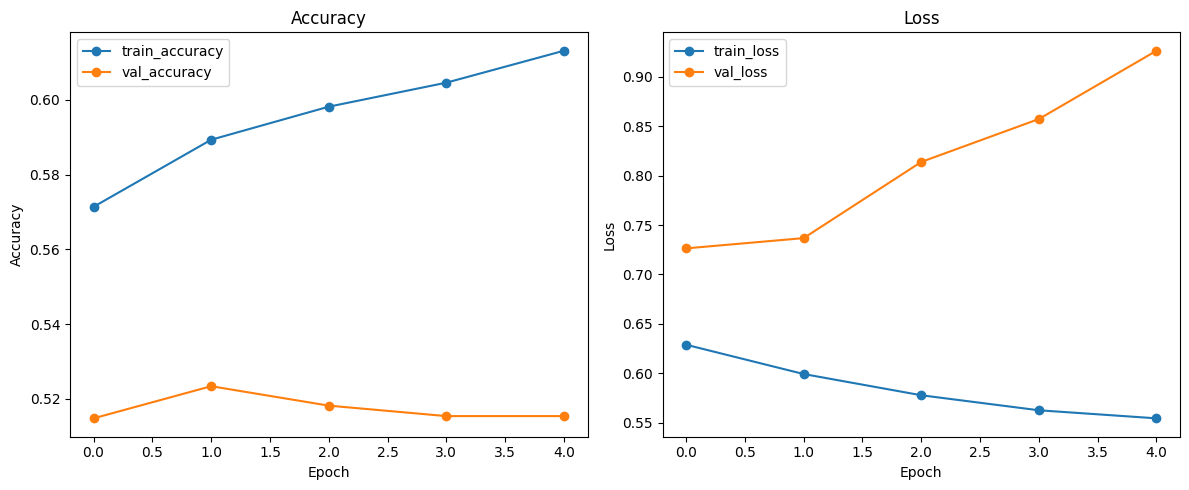

In [40]:
import matplotlib.pyplot as plt

# Plot accuracy and loss from training history
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history.get('accuracy', []), marker='o', label='train_accuracy')
plt.plot(history.history.get('val_accuracy', []), marker='o', label='val_accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history.get('loss', []), marker='o', label='train_loss')
plt.plot(history.history.get('val_loss', []), marker='o', label='val_loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Predictions on a few new example reviews:

In [43]:
new_reviews = [
    "this movie was fantastic",
    "the film was terrible and boring",
    "i really loved this product",
    "worst experience ever"
]

new_reviews_tf = tf.constant([s for s in new_reviews], dtype=tf.string)

predictions = model.predict(new_reviews_tf)
print(predictions)
print("Labels (0/1):", (predictions > 0.5).astype(int))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[0.49787802]
 [0.49787802]
 [0.49787802]
 [0.48861194]]
Labels (0/1): [[0]
 [0]
 [0]
 [0]]


In [44]:
for review, prediction in zip(new_reviews, predictions):
    
    if prediction > 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Prediction:", prediction[0])
    print("Sentiment:", sentiment)
    print()

Review: this movie was fantastic
Prediction: 0.49787802
Sentiment: Negative

Review: the film was terrible and boring
Prediction: 0.49787802
Sentiment: Negative

Review: i really loved this product
Prediction: 0.49787802
Sentiment: Negative

Review: worst experience ever
Prediction: 0.48861194
Sentiment: Negative



**Model 1 is weak** because the architecture does not fit the data well: SimpleRNN does not handle long reviews efficiently, and the model also
learns from the padding added to the sequences, which degrades its performance a lot. That is why it stays at about 51% accuracy on validation
and test — close to random guessing — and predicts almost the same probability (~0.49) for every example review.

### 6.2 Model 2 — LSTM

In [56]:
lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(x_test_tf, y_test_tf)

lstm_results = {
    "model": "LSTM",
    "val_accuracy_final": lstm_history.history['val_accuracy'][-1],
    "val_accuracy_best": max(lstm_history.history['val_accuracy']),
    "test_accuracy": lstm_test_accuracy,
    "test_loss": lstm_test_loss,
}

comparison_df = pd.DataFrame([simple_rnn_results, lstm_results])
comparison_df["imbunatatire_test_accuracy_vs_rnn"] = comparison_df["test_accuracy"] - simple_rnn_results["test_accuracy"]
comparison_df.round(4)


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8794 - loss: 0.3439


,model,val_accuracy_final,val_accuracy_best,test_accuracy,test_loss,imbunatatire_test_accuracy_vs_rnn
0,SimpleRNN,0.5154,0.5234,0.5120,0.9303,0.0000
1,LSTM,0.8750,0.8802,0.8794,0.3439,0.3674


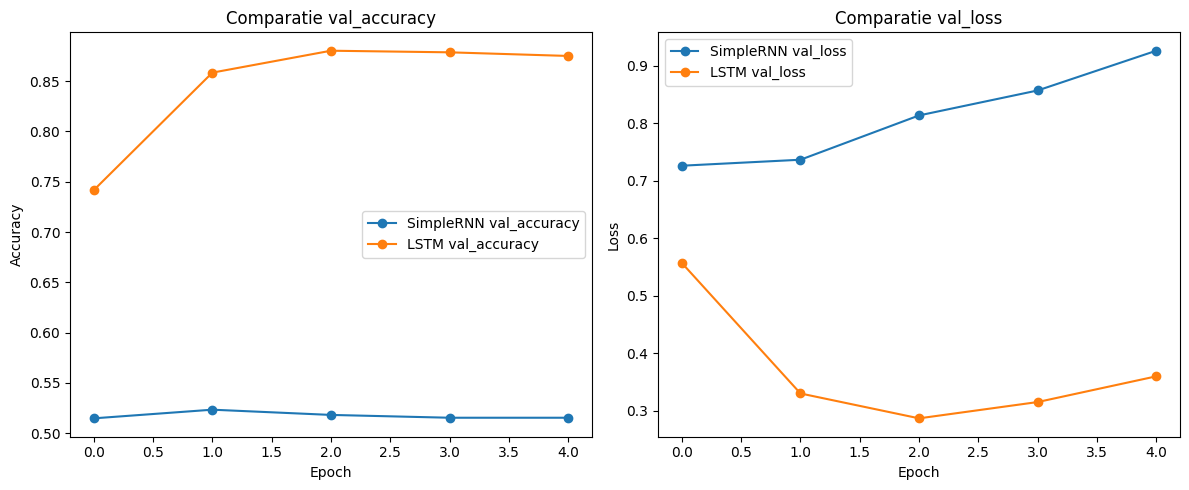

In [57]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history.get('val_accuracy', []), marker='o', label='SimpleRNN val_accuracy')
plt.plot(lstm_history.history.get('val_accuracy', []), marker='o', label='LSTM val_accuracy')
plt.title('Comparatie val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history.get('val_loss', []), marker='o', label='SimpleRNN val_loss')
plt.plot(lstm_history.history.get('val_loss', []), marker='o', label='LSTM val_loss')
plt.title('Comparatie val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


LSTM brings a major improvement over SimpleRNN: **0.8802** best validation accuracy and **0.8794** test accuracy,
compared with 0.5234 and 0.5120 for model 1. LSTM keeps information across long sequences much better, and with `mask_zero=True` it ignores the useless padding.

### 6.3 Model 3 — GRU

In [60]:
gru_test_loss, gru_test_accuracy = gru_model.evaluate(x_test_tf, y_test_tf)

gru_results = {
    "model": "GRU",
    "val_accuracy_final": gru_history.history['val_accuracy'][-1],
    "val_accuracy_best": max(gru_history.history['val_accuracy']),
    "test_accuracy": gru_test_accuracy,
    "test_loss": gru_test_loss,
}

comparison_df = pd.DataFrame([simple_rnn_results, lstm_results, gru_results])
comparison_df["imbunatatire_test_accuracy_vs_rnn"] = comparison_df["test_accuracy"] - simple_rnn_results["test_accuracy"]
comparison_df.round(4)


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8740 - loss: 0.4849


,model,val_accuracy_final,val_accuracy_best,test_accuracy,test_loss,imbunatatire_test_accuracy_vs_rnn
0,SimpleRNN,0.5154,0.5234,0.5120,0.9303,0.0000
1,LSTM,0.8750,0.8802,0.8794,0.3439,0.3674
2,GRU,0.8738,0.8960,0.8740,0.4849,0.3620


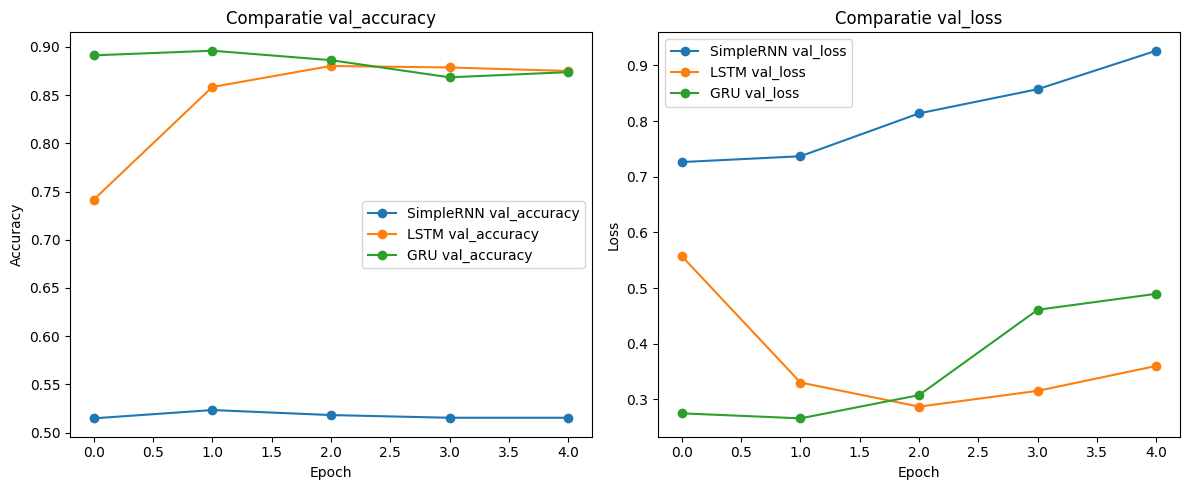

In [61]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history.get('val_accuracy', []), marker='o', label='SimpleRNN val_accuracy')
plt.plot(lstm_history.history.get('val_accuracy', []), marker='o', label='LSTM val_accuracy')
plt.plot(gru_history.history.get('val_accuracy', []), marker='o', label='GRU val_accuracy')
plt.title('Comparatie val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history.get('val_loss', []), marker='o', label='SimpleRNN val_loss')
plt.plot(lstm_history.history.get('val_loss', []), marker='o', label='LSTM val_loss')
plt.plot(gru_history.history.get('val_loss', []), marker='o', label='GRU val_loss')
plt.title('Comparatie val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


GRU is also far better than SimpleRNN: **0.8960** best validation accuracy and **0.8740** test accuracy.
Compared with LSTM, GRU reached a slightly higher best validation accuracy but a slightly lower test accuracy (0.8740 vs 0.8794),
so in this experiment LSTM is marginally more stable on the test set. GRU's validation loss rises after epoch 2, a sign of overfitting.

## 7. Conclusions

| Model | Best val accuracy | Test accuracy | Test loss |
|---|---|---|---|
| SimpleRNN | 0.5234 | 0.5120 | 0.9303 |
| LSTM | 0.8802 | **0.8794** | **0.3439** |
| GRU | **0.8960** | 0.8740 | 0.4849 |

- `SimpleRNN` is clearly the weakest of the three models.
- Both `LSTM` and `GRU` handle long-range dependencies in text much better and ignore the padding through `mask_zero=True`.
- `GRU` had the best peak validation accuracy, while `LSTM` obtained the best test result: gated recurrent models (LSTM and GRU) are far superior to `SimpleRNN`,
  with a very small advantage for `LSTM` on the test set.